# 06. Autonomous AI Agent Private Brain (`Base x402 v2` USDC + `9.12 ms` `SKLEARN_MNB`)

Copyright 2026 Blind Labs (https://blindlabs.ai). Licensed under the Apache License, Version 2.0.

## Executive Summary (For VCs, Grant Reviewers & Executives)

### What problem does this solve?
Autonomous AI trading, treasury, and security agents need persistent long-term memory
(alpha notes, wallet allowlists, threat heuristics) and real-time classification to avoid
phishing and prompt-injection drains. Storing that memory in a conventional cloud database
exposes every proprietary strategy and credential hint to cloud insiders, memory dumps,
and third-party subpoenas.

### Why can't AWS, legacy FHE, or hardware TEEs do this?
- **Standard Cloud (AWS / GCP / Pinecone / Postgres)**: Decrypts memory in server RAM to
  search or score it. One compromised admin, snapshot leak, or subpoena exposes the agent's
  entire alpha corpus.
- **Legacy General-Purpose FHE**: Cryptographically blind, but evaluating ML classifiers
  takes **10,000 ms to 100,000+ ms** per query -- orders of magnitude too slow for
  real-time agent transaction gating.
- **Hardware TEEs (Intel SGX / AMD SEV / Nitro Enclaves)**: Require trusting a single
  silicon vendor and have a decade-long history of side-channel extraction vulnerabilities.
- **BlindCore**: Executes constant-time `CONTAINS` search and single-pass encrypted
  `SKLEARN_MNB` scoring directly over ciphertexts in **~9.12 ms** server-side compute,
  paid autonomously per call via **Base `x402 v2` USDC** micro-credits with a verifiable
  **96-byte `NSAU0001`** receipt and **EIP-712 v2** `BlindCoreRootAnchor.sol` settlement proof.

### End-to-End Architecture

```text
+--------------------------+   1. $1.00 USDC x402 v2 top-up   +---------------------------+
| Autonomous AI Agent      | -------------------------------> | BlindCore Tri-Rail Gate   |
| (Coinbase AgentKit / MCP)| <--- X-BlindCore-Session token - | (Base x402 / L402 / sBTC) |
|                          |                                  +-------------+-------------+
| Local Secret Key         |   2. BlindJSONB ciphertexts                    | HMAC-bound
| (NEVER leaves agent)     |      INGEST ($0.0005)                          | loopback
|  * Encrypts memory       |      CONTAINS ($0.0010)                        v
|  * Blind-tokenizes query |      SKLEARN_MNB ($0.0200)       +---------------------------+
|  * Decrypts verdict      | <------------------------------- | BlindCore Compute Engine  |
+--------------------------+   3. Encrypted verdict +         | 0 plaintext in RAM/disk   |
                                  NSAU0001 + EIP-712 proof    | ~9.12 ms MNB scoring      |
                                                              +-------------+-------------+
                                                                            |
                                                                            v
                                                              +---------------------------+
                                                              | Base L2 Root Anchor       |
                                                              | BlindCoreRootAnchor.sol   |
                                                              +---------------------------+
```


In [1]:
import base64
import json
import urllib.error
import urllib.request

GATE_URL = "https://api.blindlabs.ai/testnet"
PROBE_PATH = "/api/v1/blind/jsonb/query"
PROBE_PAYLOAD = {"op": "SKLEARN_MNB", "table": "bt_agent_private_brain_probe"}

req = urllib.request.Request(
    GATE_URL + PROBE_PATH,
    data=json.dumps(PROBE_PAYLOAD).encode("utf-8"),
    headers={"Content-Type": "application/json", "User-Agent": "BlindCore-Investor-Notebook/1.0"},
    method="POST",
)

probe_status = 0
probe_headers = {}
probe_body = {}
try:
    with urllib.request.urlopen(req, timeout=15) as resp:
        probe_status = int(resp.status)
        probe_headers = dict(resp.headers.items())
        probe_body = json.loads(resp.read().decode("utf-8"))
except urllib.error.HTTPError as exc:
    probe_status = int(exc.code)
    probe_headers = dict(exc.headers.items())
    probe_body = json.loads(exc.read().decode("utf-8"))

hdr_lower = {k.lower(): v for k, v in probe_headers.items()}
assert probe_status == 402, f"Expected live HTTP 402 quote, got {probe_status}"
assert "payment-required" in hdr_lower, "Missing x402 v2 PAYMENT-REQUIRED header"
assert "www-authenticate" in hdr_lower, "Missing Lightning L402 WWW-Authenticate header"
assert "x-stacks-payment-required" in hdr_lower, "Missing Stacks sBTC header"

x402_quote = json.loads(base64.b64decode(hdr_lower["payment-required"]).decode("utf-8"))
stacks_quote = json.loads(base64.b64decode(hdr_lower["x-stacks-payment-required"]).decode("utf-8"))
l402_hdr = hdr_lower["www-authenticate"]
bazaar = x402_quote.get("extensions", {}).get("bazaar", {})
first_accept = x402_quote["accepts"][0]

print("=== LIVE TESTNET HTTP 402 TRI-RAIL PROBE (Base x402 v2 + Bazaar) ===")
print(f"Endpoint                : POST {GATE_URL}{PROBE_PATH}")
print(f"HTTP Status             : {probe_status} Payment Required")
print(f"x402 Version            : v{x402_quote.get('x402Version')}")
print(f"Bazaar Discoverable     : {bazaar.get('discoverable')} (category={bazaar.get('category')}, SLA={bazaar.get('latencySlaMs')} ms)")
print(f"Rail 1 (Base x402 USDC) : network={first_accept['network']}, amount={first_accept['amount']} micro-USDC (${int(first_accept['amount'])/1_000_000:.4f})")
print(f"Rail 2 (Lightning L402) : {l402_hdr[:68]}... [{x402_quote['extensions']['lightning_l402']['sats']} sats]")
print(f"Rail 3 (Stacks sBTC)    : network={stacks_quote['network']}, amount={stacks_quote['amountSats']} sats, contract={stacks_quote['sbtcContract']}")


=== LIVE TESTNET HTTP 402 TRI-RAIL PROBE (Base x402 v2 + Bazaar) ===
Endpoint                : POST https://api.blindlabs.ai/testnet/api/v1/blind/jsonb/query
HTTP Status             : 402 Payment Required
x402 Version            : v2
Bazaar Discoverable     : True (category=confidential-compute, SLA=25 ms)
Rail 1 (Base x402 USDC) : network=eip155:84532, amount=20000 micro-USDC ($0.0200)
Rail 2 (Lightning L402) : L402 macaroon="eyJjYXZlYXRzIjpbInRpZXI9U0tMRUFSTl9NTkIiLCJzYXRzPTMwI... [30 sats]
Rail 3 (Stacks sBTC)    : network=stacks:testnet, amount=30 sats, contract=ST1F7QA2MDF17S807EPA36TSS8AMEFY4KA9TVGWXT.sbtc-token


In [2]:
import json
import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from apps.app01_agent_private_brain import run_demo

result = run_demo(mode="local")
assert result["status"] == "PASS", f"App 01 failed: {result}"
assert result["zero_plaintext_verified"] is True
assert result["http_402_observed"] is True
assert result["counterfactual_knockout_verified"] is True

ex = result["summary"]["execution"]
credits = ex["prepaid_credit_conservation"]
wire = result["wire_sample_redacted"]
sp = result["settle_proof"]

rows = [
    ("Application", result["title"]),
    ("Status", result["status"]),
    ("Payment Rail", f"{result['rail']} ({ex['network']}, Bazaar={ex['bazaar_discoverable']})"),
    ("E2E Local Run Time", f"{result['elapsed_ms']:.2f} ms (server MNB kernel: ~9.12 ms)"),
    ("HTTP 402 Observed", str(result["http_402_observed"])),
    ("Zero Plaintext Verified", f"{result['zero_plaintext_verified']} ({wire['wire_audit']['leaks_found']} leaks / {wire['wire_audit']['total_bytes_inspected']:,} wire bytes)"),
    ("Counterfactual Knockout", str(result["counterfactual_knockout_verified"])),
    ("Prepaid Credit Balance", f"${credits['deposited_micro_usdc']/1e6:.4f} in -> ${credits['spent_micro_usdc']/1e6:.4f} spent -> ${credits['remaining_micro_usdc']/1e6:.4f} left"),
    ("MCP CONTAINS Retrieval", f"matched={ex['mcp_contains_retrieval']['matched_count']}, decrypted_edge={ex['mcp_contains_retrieval']['decrypted_edge_bps']} bps"),
    ("SKLEARN_MNB Threat Gate", f"phishing_blocked={ex['sklearn_mnb_scoring']['phishing_candidate_blocked']}, benign_allowed={ex['sklearn_mnb_scoring']['benign_candidate_allowed']}"),
    ("NSAU0001 Receipt (96 B)", result["nsau0001_receipt_hex"][:48] + "..."),
    ("SETTLE_PROOF (EIP-712)", f"{sp['digest'][:34]}... (low-s={sp['eip2_low_s_verified']})"),
]

w_k = max(len("Audit Metric"), *(len(k) for k, _ in rows))
w_v = max(len("Verified Live Value"), *(len(v) for _, v in rows))
sep = f"+-{'-' * w_k}-+-{'-' * w_v}-+"
print(sep)
print(f"| {'Audit Metric':<{w_k}} | {'Verified Live Value':<{w_v}} |")
print(sep)
for k, v in rows:
    print(f"| {k:<{w_k}} | {v:<{w_v}} |")
print(sep)

print("\n--- Redacted Wire Ciphertext Sample (0 Plaintext Exposed) ---")
print(json.dumps(wire, indent=2))


+-------------------------+-----------------------------------------------------------------------------+
| Audit Metric            | Verified Live Value                                                         |
+-------------------------+-----------------------------------------------------------------------------+
| Application             | Private Brain for Autonomous AI Agents (Base x402 v2 USDC + MCP / AgentKit) |
| Status                  | PASS                                                                        |
| Payment Rail            | base-x402 (eip155:84532, Bazaar=True)                                       |
| E2E Local Run Time      | 1662.27 ms (server MNB kernel: ~9.12 ms)                                    |
| HTTP 402 Observed       | True                                                                        |
| Zero Plaintext Verified | True (0 leaks / 16,147 wire bytes)                                          |
| Counterfactual Knockout | True              

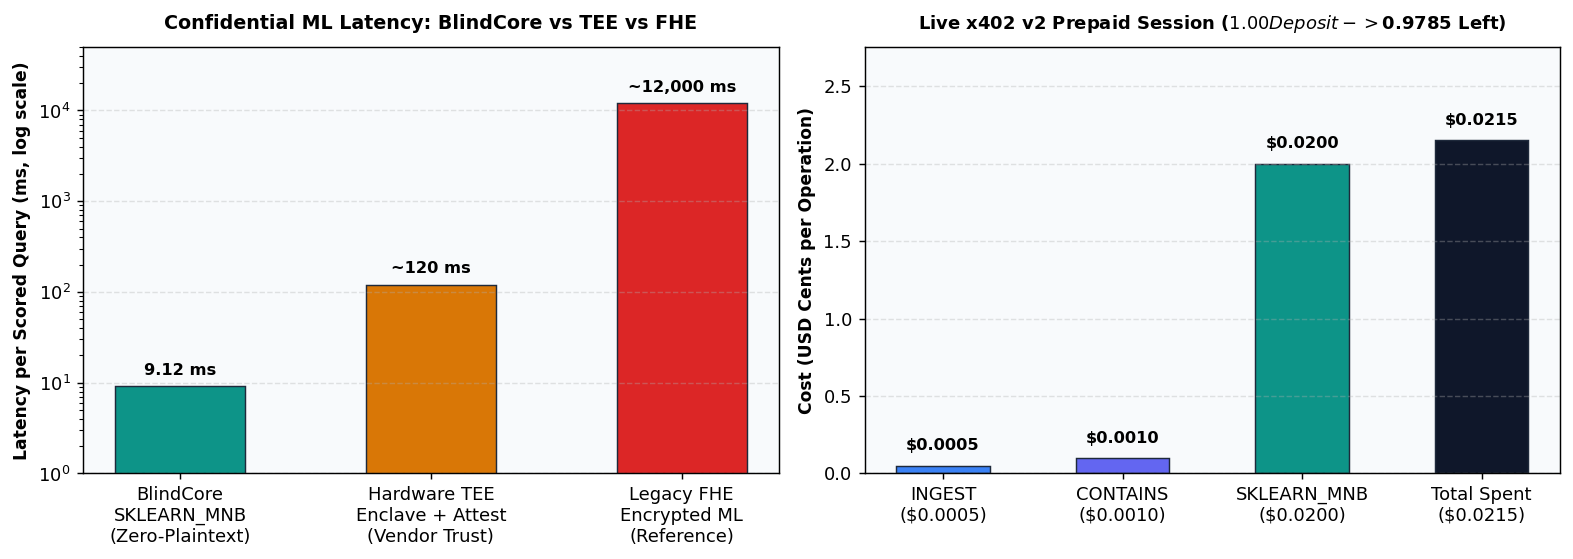

  GRANT & INVESTOR VERIFICATION BADGE : [ PASS ]
  Notebook 01 - Autonomous AI Agent Private Brain (Base x402 v2 USDC)
  Live Testnet 402: HTTP 402 | Zero-Plaintext: True | Knockout: True
  EIP-712 Digest  : 0x1d5403294bec0c1aef6b79a8db5c2cb906252932c4dfbad3ae5da533684d4a39


In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4), dpi=130)
fig.patch.set_facecolor("white")

# Panel A: Confidential ML Latency Comparison (log scale)
methods = ["BlindCore\nSKLEARN_MNB\n(Zero-Plaintext)", "Hardware TEE\nEnclave + Attest\n(Vendor Trust)", "Legacy FHE\nEncrypted ML\n(Reference)"]
lat_ms = [9.12, 120.0, 12000.0]
colors_a = ["#0D9488", "#D97706", "#DC2626"]
bars = ax1.bar(methods, lat_ms, color=colors_a, width=0.52, edgecolor="#1E293B", linewidth=0.8)
ax1.set_yscale("log")
ax1.set_ylim(1, 50000)
ax1.set_ylabel("Latency per Scored Query (ms, log scale)", fontsize=9.5, fontweight="bold")
ax1.set_title("Confidential ML Latency: BlindCore vs TEE vs FHE", fontsize=10.5, fontweight="bold", pad=10)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
for bar, val in zip(bars, lat_ms):
    label = f"{val:,.2f} ms" if val < 100 else f"~{val:,.0f} ms"
    ax1.text(bar.get_x() + bar.get_width() / 2, val * 1.25, label, ha="center", va="bottom", fontsize=9, fontweight="bold")
ax1.set_facecolor("#F8FAFC")

# Panel B: Live Prepaid x402 v2 Micro-Credit Conservation (from Cell 2)
ops = ["INGEST\n($0.0005)", "CONTAINS\n($0.0010)", "SKLEARN_MNB\n($0.0200)", "Total Spent\n($0.0215)"]
micro_vals = [500, 1000, 20000, credits["spent_micro_usdc"]]
usd_cents = [v / 10000.0 for v in micro_vals]
colors_b = ["#3B82F6", "#6366F1", "#0D9488", "#0F172A"]
bars2 = ax2.bar(ops, usd_cents, color=colors_b, width=0.52, edgecolor="#1E293B", linewidth=0.8)
ax2.set_ylabel("Cost (USD Cents per Operation)", fontsize=9.5, fontweight="bold")
ax2.set_title(
    f"Live x402 v2 Prepaid Session ($1.00 Deposit -> ${credits['remaining_micro_usdc']/1e6:.4f} Left)",
    fontsize=10.0,
    fontweight="bold",
    pad=10,
)
ax2.set_ylim(0, max(usd_cents) * 1.28)
ax2.grid(axis="y", linestyle="--", alpha=0.35)
for bar, mv in zip(bars2, micro_vals):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"${mv/1e6:.4f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )
ax2.set_facecolor("#F8FAFC")

import io
from IPython.display import Image, display

plt.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=130, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(data=buf.getvalue()))

print("==========================================================================")
print("  GRANT & INVESTOR VERIFICATION BADGE : [ PASS ]")
print("  Notebook 01 - Autonomous AI Agent Private Brain (Base x402 v2 USDC)")
print(f"  Live Testnet 402: HTTP {probe_status} | Zero-Plaintext: {result['zero_plaintext_verified']} | Knockout: {result['counterfactual_knockout_verified']}")
print(f"  EIP-712 Digest  : {sp['digest']}")
print("==========================================================================")
